## Hipotesis 3: Satisfacción laboral y consideración de cambio de rol o carrera

**Población de estudio:** Desarrolladores encuestados con respuestas válidas en su nivel de satisfacción laboral e intención de cambio de empleo (`df_clean`).

**Hipótesis Nula ($H_0$):** No existe una relación o asociación estadísticamente significativa entre los niveles de satisfacción en el trabajo actual (`JobSat`) y la consideración o intención de un cambio de rol o carrera (`SO_JobSearchStatus`).

**Hipótesis Alternativa ($H_1$):** Existe una relación estadísticamente significativa entre los niveles de satisfacción laboral en el trabajo actual y la consideración o intención de un cambio de rol o carrera.

**Atributos involucrados:**
- `JobSat`: Nivel de satisfacción en el trabajo actual (cualitativa ordinal).
- `SO_JobSearchStatus`: Estado de búsqueda de empleo / consideración de cambio de rol (cualitativa categórica).

**Justificación:** Analizar los factores asociados a la rotación laboral es central en la industria tecnológica. Probar empíricamente si la baja satisfacción laboral influye directamente en la búsqueda de nuevas oportunidades permite validar la satisfacción como predictor clave del *turnover* voluntario.

<Figure size 1000x600 with 0 Axes>

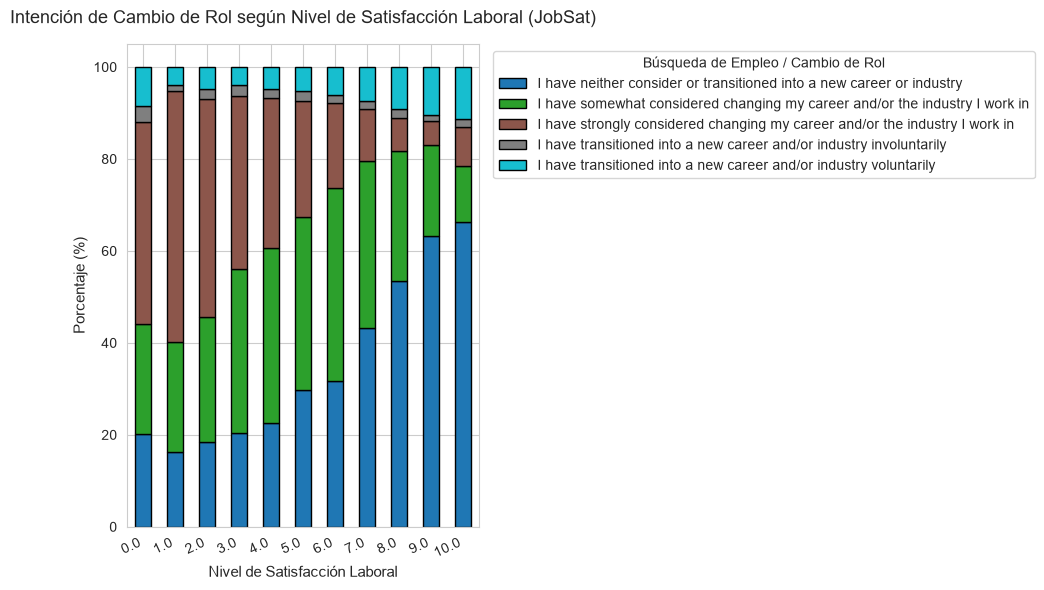

In [13]:
# 1. Filtrar registros con respuestas válidas en ambas variables
col_sat = "JobSat"
col_cambio = (
    "SO_JobSearchStatus"
    if "SO_JobSearchStatus" in df_clean.columns
    else "NewRole"
)

df_4c = df_clean.dropna(subset=[col_sat, col_cambio]).copy()

# 2. Generar tabla de contingencia porcentual por nivel de satisfacción
tabla_pct = (
    pd.crosstab(df_4c[col_sat], df_4c[col_cambio], normalize="index") * 100
)

# 3. Gráfico de barras apiladas
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

ax = tabla_pct.plot(
    kind="bar", stacked=True, colormap="tab10", figsize=(10, 6), edgecolor="black"
)

plt.title(
    "Intención de Cambio de Rol según Nivel de Satisfacción Laboral (JobSat)",
    fontsize=13,
    pad=15,
)
plt.xlabel("Nivel de Satisfacción Laboral", fontsize=11)
plt.ylabel("Porcentaje (%)", fontsize=11)
plt.legend(
    title="Búsqueda de Empleo / Cambio de Rol",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=10,
)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.show()

En el gráfico se observa visualmente que a medida que disminuye el nivel de satisfacción laboral (avanzando hacia categorías de insatisfacción), se incrementa sustancialmente el porcentaje de desarrolladores que buscan activamente un empleo o están abiertos a nuevas oportunidades. Al tratarse de dos variables categóricas (cualitativas), no corresponden las pruebas de comparación de medias (como T-Student o ANOVA). Por lo tanto, aplicaremos el test no paramétrico de **Chi-cuadrado ($\chi^2$) de Independencia** junto con el indicador **V de Cramér** para medir la intensidad del efecto.

In [14]:
# 1. Matriz de frecuencias absolutas para Chi-cuadrado
tabla_contingencia = pd.crosstab(df_4c[col_sat], df_4c[col_cambio])

# 2. Ejecutar el test de Chi-cuadrado de independencia
chi2_stat, p_value, dof, expected = stats.chi2_contingency(tabla_contingencia)

# 3. Calcular el tamaño del efecto (V de Cramér)
n = tabla_contingencia.sum().sum()
min_dim = min(tabla_contingencia.shape) - 1
cramer_v = np.sqrt(chi2_stat / (n * min_dim))

# 4. Mostrar resultados numéricos
print("--- TEST DE CHI-CUADRADO DE INDEPENDENCIA ---")
print(f"Estadístico Chi2 : {chi2_stat:.4f}")
print(f"Grados de libertad: {dof}")
print(f"Valor p (p-value) : {p_value:.4e}")
print(f"V de Cramér       : {cramer_v:.4f}\n")

# 5. Veredicto final dinámico según p-valor
if p_value < 0.05:
    print("Conclusión: Rechazamos la hipótesis nula (H0).")
    print(
        "Hay evidencia estadística suficiente para afirmar que los niveles de satisfacción laboral "
        "están significativamente relacionados con la consideración de un cambio de rol o carrera."
    )
else:
    print("Conclusión: No podemos rechazar la hipótesis nula (H0).")
    print(
        "No hay evidencia estadística suficiente para afirmar una relación entre la satisfacción laboral "
        "y la consideración de un cambio de rol o carrera."
    )

--- TEST DE CHI-CUADRADO DE INDEPENDENCIA ---
Estadístico Chi2 : 3865.6071
Grados de libertad: 40
Valor p (p-value) : 0.0000e+00
V de Cramér       : 0.1962

Conclusión: Rechazamos la hipótesis nula (H0).
Hay evidencia estadística suficiente para afirmar que los niveles de satisfacción laboral están significativamente relacionados con la consideración de un cambio de rol o carrera.
